# 11 - Random Forest on full BGL

A supervised Random Forest on the 20-line window count vectors, with the same three ways of handling the class imbalance as notebook 07 (HDFS).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models.supervised import evaluate_rf, shap_top_events, top_importances, train_rf
from src.models.unsupervised import time_split

pd.set_option("display.max_colwidth", 100)
DOCS = ROOT / "docs"

counts = pd.read_parquet(ROOT / "data" / "processed" / "bgl_counts.parquet")
templates = pd.read_csv(ROOT / "data" / "processed" / "bgl_templates.csv").set_index("EventId")["template"]
event_cols = list(counts.filter(regex=r"^E\d+$").columns)

## Train / test split

Same split as notebook 10: first 70% of windows by window index for training, last 30% for testing. The model trains on both classes.

In [2]:
train, test = time_split(counts, train_frac=0.7, order_col="window")
X_train, y_train = train[event_cols], train["Label"]
X_test, y_test = test[event_cols], test["Label"]

pd.DataFrame({
    "windows": [len(train), len(test)],
    "anomalous windows": [y_train.sum(), y_test.sum()],
}, index=["train (first 70%)", "test (last 30%)"])

,windows,anomalous windows
train (first 70%),166178,14949
test (last 30%),71220,5312


## Train and evaluate

100 trees each: (a) no imbalance handling, (b) `class_weight='balanced'`, (c) SMOTE on the training set only. Training time includes SMOTE.

In [3]:
methods = {"none": "No imbalance handling", "balanced": "class_weight='balanced'", "smote": "SMOTE"}
models, rows = {}, []
for key, label in methods.items():
    models[key], fit_s = train_rf(X_train, y_train, method=key)
    rows.append({"method": label, **evaluate_rf(models[key], X_test, y_test), "train_seconds": fit_s})

results = pd.DataFrame(rows)[["method", "precision", "recall", "f1", "false_alarm_rate", "roc_auc", "train_seconds"]]
DOCS.mkdir(exist_ok=True)
results.round(4).to_csv(DOCS / "bgl_rf_results.csv", index=False)
results.style.format({c: "{:.4f}" for c in ["precision", "recall", "f1", "false_alarm_rate", "roc_auc"]} | {"train_seconds": "{:.1f}"}).hide(axis="index")

method,precision,recall,f1,false_alarm_rate,roc_auc,train_seconds
No imbalance handling,0.9951,0.5348,0.6957,0.0002,0.9167,4.5
class_weight='balanced',0.9934,0.5365,0.6967,0.0003,0.9170,5.9
SMOTE,0.9944,0.5373,0.6976,0.0002,0.9167,16.4


## Templates not seen in training

Anomalous test windows that contain a template which never appears in the training part (normal or anomalous), and the recall on them compared with the other anomalous windows.

In [4]:
unseen = X_train.sum(axis=0) == 0
has_unseen = (X_test.loc[:, unseen].sum(axis=1) > 0).to_numpy()
anomalous = y_test.to_numpy() == 1
print(f"Templates never seen in the training part: {unseen.sum()} of {len(event_cols)}")
print(f"Anomalous test windows with such a template: {(anomalous & has_unseen).sum():,} of {anomalous.sum():,}\n")

pd.DataFrame({
    methods[key]: {
        "recall, windows with unseen template": (model.predict(X_test)[anomalous & has_unseen] == 1).mean(),
        "recall, other anomalous windows": (model.predict(X_test)[anomalous & ~has_unseen] == 1).mean(),
    }
    for key, model in models.items()
}).round(3)

Templates never seen in the training part: 117 of 391
Anomalous test windows with such a template: 2,539 of 5,312



,No imbalance handling,class_weight='balanced',SMOTE
"recall, windows with unseen template",0.061,0.067,0.069
"recall, other anomalous windows",0.968,0.966,0.966


## Feature importance

Top 10 impurity-based importances for the method with the best F1.

In [5]:
best = list(methods)[results["f1"].idxmax()]
best_model = models[best]
print(f"Best method: {methods[best]}")

importances = top_importances(best_model, event_cols, templates)
importances.index += 1
importances

Best method: SMOTE


,event,importance,template
1,E18,0.271174,data TLB error interrupt
2,E3,0.228631,generating core.<NUM>
3,E125,0.130790,data storage interrupt
4,E11,0.044292,<NUM> double-hummer alignment exceptions
5,E218,0.029329,ciod: Error reading message prefix after <*> on CioStream socket to <IP>: <*> <*> <*> <*>
6,E263,0.026784,rts: kernel terminated for reason <NUM>
7,E159,0.024110,<NUM> floating point alignment exceptions
8,E17,0.017880,ciod: failed to read message prefix on control stream (CioStream socket to <IP>
9,E272,0.017572,Lustre mount FAILED : <*> : point /p/gb1
10,E54,0.016294,rts panic! - stopping execution


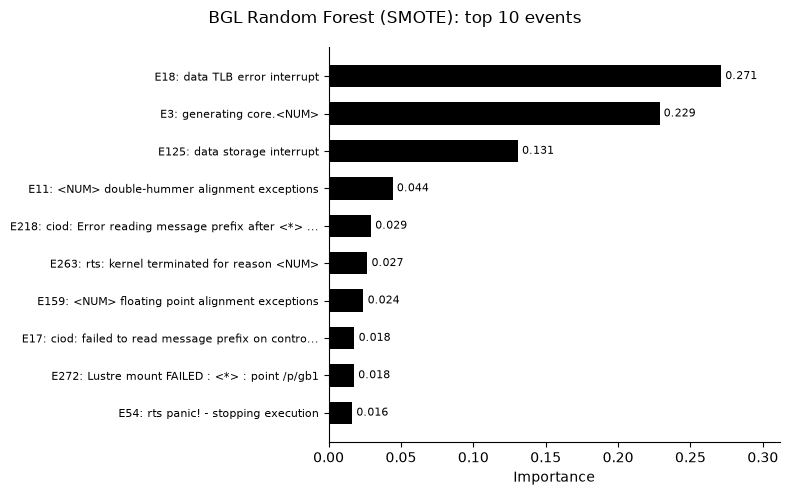

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
labels = [f"{e}: {t[:45]}{'...' if len(t) > 45 else ''}" for e, t in zip(importances["event"], importances["template"])]
ax.barh(labels[::-1], importances["importance"][::-1], color="black", height=0.6)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3, fontsize=8)

ax.set_xlabel("Importance")
fig.suptitle(f"BGL Random Forest ({methods[best]}): top 10 events")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlim(0, importances["importance"].max() * 1.15)

fig.tight_layout()
fig.savefig(DOCS / "bgl_rf_importance.png", dpi=150, facecolor="white")
plt.show()

## SHAP explanation for one detected anomaly

We take the correctly detected anomalous window with the highest anomaly probability. A count of 0 can also be evidence, since the model learns which events are missing. BGL trees are very deep (depth 80+), so SHAP compares against a sample of 100 training windows instead of its default algorithm.

In [7]:
proba = best_model.predict_proba(X_test)[:, 1]
detected = (y_test.to_numpy() == 1) & (best_model.predict(X_test) == 1)
pos = proba[detected].argmax()
x = X_test[detected].iloc[[pos]]
window = test.loc[x.index[0], "window"]

background = X_train.sample(100, random_state=42)
top3 = shap_top_events(best_model, x, event_cols, templates, background=background)
print(f"Window {window}: {proba[detected][pos]:.0%} anomaly probability. Top 3 events:")
for row in top3.itertuples():
    print(f'- "{row.template}" ({row.event}), count {row.count}: {row.shap:+.0%}')

Window 166178: 100% anomaly probability. Top 3 events:
- "Lustre mount FAILED : <*> : point /p/gb1" (E272), count 20: +70%
- "generating core.<NUM>" (E3), count 0: +13%
- "<NUM> double-hummer alignment exceptions" (E11), count 0: +4%


## HDFS vs BGL

In [8]:
hdfs = pd.read_csv(DOCS / "hdfs_rf_results.csv").set_index("method")["f1"]
pd.DataFrame({"HDFS F1": hdfs, "BGL F1": results.set_index("method")["f1"]}).round(4)

,HDFS F1,BGL F1
method,,
No imbalance handling,0.9992,0.6957
class_weight='balanced',0.9992,0.6967
SMOTE,0.9819,0.6976
